# The operational-risk validation tests

**Question:** What does each of the five operational-risk tests measure, and how much of its colour comes from the method under test rather than from the gates, the size of the simulation or the single history it is run on?


- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 03, 04 and 05 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- list the five operational-risk tests of the engine, what each measures and the committed rows of the case for them;
- say why these tests are descriptive: they have no p-value, and their lights compare a metric with gates that Contraste sets and that are not regulation;
- recompute `oprisk.benchmark_reproduction`, `oprisk.threshold_stability`, `oprisk.capital_stability`, `oprisk.sma_ilm_response` and `oprisk.scenario_influence` with the engine and compare them with the committed rows;
- see how a gate changes a light without changing the metric, and how the number of simulated years changes a light.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The generator of case C17 and its estimators live in `data-pipeline/pipeline/cases/c17/`, which is not an installed package: this notebook loads those modules by path (importing the whole `pipeline` package would import every case and its heavy dependencies). The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The variants of case C17 commit 31 test rows each (27 for the variant with tail index 1.1): one benchmark reproduction, 24 capital-stability rows (6 rungs of the estimation ladder times 4 cells of history length and collection threshold), 4 threshold-stability rows, one response of the standardised approach to a large loss and one scenario influence. The variant with tail index 1.1 has 20 capital-stability rows, four fewer, because the mean-corrected approximation does not exist there (notebook 04).

- **Files read:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` and `xi-1-1.json`, the key `tests`, plus `outputs.cells`, `outputs.truth`, `outputs.sma_response` and `outputs.scenario_influence` to recompute them.
- **Histories:** where a test needs histories, the notebook regenerates them from the committed seeds with the case's generator, loaded by path as in notebook 02, and runs the case's own estimator `replicate.estimate`, which composes the engine's functions.

The next cell loads the four documents and the generator.

In [2]:
# Load the four variant documents and the case's generator and estimator by path
ROOT = Path("../../..").resolve()
docs = {
    name: json.loads(
        (ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

for name, doc in docs.items():
    print(
        name, "| tests committed:", len(doc["tests"]), "| baked by riskvalidation",
        doc["provenance"]["riskvalidation_version"]
    )

xi-0-6 | tests committed: 31 | baked by riskvalidation 1.0.1
xi-0-8 | tests committed: 31 | baked by riskvalidation 1.0.1
xi-0-96 | tests committed: 31 | baked by riskvalidation 1.0.1
xi-1-1 | tests committed: 27 | baked by riskvalidation 1.0.1


## Method

### Step 1: the five tests and what a row holds

Every test returns a `TestResult`. For the operational-risk family the fields `p_value`, `alpha_amber` and `alpha_red` are empty by design: the tests are **descriptive**. A metric is compared with two gates that travel in the row, in `policy_version` and in `extras["thresholds"]`, so that a reader can see why a light has its colour. The gates are Contraste's internal choices for this case, not regulatory thresholds.

| Test | Metric | What it asks |
|---|---|---|
| `oprisk.benchmark_reproduction` | the largest deviation over its tolerance | does the engine reproduce Shevchenko's benchmark? |
| `oprisk.threshold_stability` | range of the fitted tail index across thresholds | does the tail index drift with the threshold? |
| `oprisk.capital_stability` | (p75 - p25) / truth, and the bias median / truth - 1 | is the capital stable across histories and unbiased against the truth? |
| `oprisk.sma_ilm_response` | ILM after minus ILM before one added loss | does the SMA multiplier jump with one large loss? |
| `oprisk.scenario_influence` | largest absolute influence of one scenario | does one scenario move the capital too much? |

The next cell counts the committed rows of each test by light for each variant and checks that none holds a p-value.

In [3]:
# Count the committed rows of each test by light, and check that no row holds a p-value
for name, doc in docs.items():
    counts = {}
    for row in doc["tests"]:
        counts.setdefault(row["test_id"], {}).setdefault(row["light"], 0)
        counts[row["test_id"]][row["light"]] += 1
    print(name, "| rows with a p-value:", sum(row["p_value"] is not None for row in doc["tests"]))
    for test_id, by_light in counts.items():
        print("   %-32s %s" % (test_id, by_light))
print("committed rows in total:", sum(len(doc["tests"]) for doc in docs.values()))

xi-0-6 | rows with a p-value: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'amber': 1}
xi-0-8 | rows with a p-value: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'green': 1}
xi-0-96 | rows with a p-value: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 24}
   oprisk.threshold_stability       {'green': 4}
   oprisk.sma_ilm_response          {'red': 1}
   oprisk.scenario_influence        {'green': 1}
xi-1-1 | rows with a p-value: 0
   oprisk.benchmark_reproduction    {'green': 1}
   oprisk.capital_stability         {'red': 20}
   oprisk.threshold_stability       {'green': 4}

### Step 2: the benchmark, and why its light depends on the years

The reproduction test of notebook 03 is green in all four documents. Its Monte Carlo quantile is the weak component: the standard error falls like the square root of the number of years, so the same test with fewer simulated years can turn red. The next cell recomputes the test with the Panjer and Fourier quantiles of notebook 03 and a Monte Carlo of only 200,000 years instead of the 1,000,000 of the committed row.

In [4]:
# The benchmark test with a Monte Carlo of 200,000 years instead of 1,000,000
moments = aggregate.compound_poisson_moments(100.0, "lognormal", (0.0, 2.0))
severity_masses = aggregate.discretise_severity("lognormal", (0.0, 2.0), 1.0, 6000)
q_panjer = aggregate.quantile_from_pmf(aggregate.panjer_recursion("poisson", (100.0,), severity_masses), 1.0, 0.999)
q_fft = aggregate.quantile_from_pmf(aggregate.fft_aggregate("poisson", (100.0,), severity_masses), 1.0, 0.999)
short_run = aggregate.simulate_annual_losses("poisson", (100.0,), "lognormal", (0.0, 2.0), 200_000, 2010)
q_mc, se_mc = aggregate.mc_quantile(short_run.losses, 0.999)
bench = oprisk_tests.benchmark_reproduction(
    (moments.mean, moments.variance, moments.skewness), {"monte-carlo": q_mc, "panjer": q_panjer, "fft": q_fft},
    moment_rel_tol=1e-5
)
committed_bench = next(row for row in docs["xi-0-8"]["tests"] if row["test_id"] == "oprisk.benchmark_reproduction")
print(
    "Monte Carlo, 200000 years: q = %.1f (standard error %.1f) | published continuous quantile 5853.1" % (q_mc, se_mc)
)
print(
    "recomputed: metric %.3f, light %s | committed (1000000 years): metric %.3f, light %s" % (
        bench.metric, bench.light.value, committed_bench["metric"], committed_bench["light"]
    )
)

Monte Carlo, 200000 years: q = 6290.7 (standard error 263.7) | published continuous quantile 5853.1
recomputed: metric 7.476, light red | committed (1000000 years): metric 0.197, light green


The benchmark test depends on the simulation behind its Monte Carlo quantile. The next cell reruns it with six simulation sizes, from 25,000 to 800,000 years, and draws the metric against the years with each point coloured by the light the engine returns.

years   25000 | q =  6733.9 (se  380.4) | metric  15.049 | light red
years   50000 | q =  6743.2 (se  280.0) | metric  15.208 | light red
years  100000 | q =  6670.8 (se  224.5) | metric  13.970 | light red
years  200000 | q =  6290.7 (se  263.7) | metric   7.476 | light red
years  400000 | q =  5949.0 (se  123.8) | metric   1.639 | light amber
years  800000 | q =  5929.5 (se   84.6) | metric   1.306 | light amber


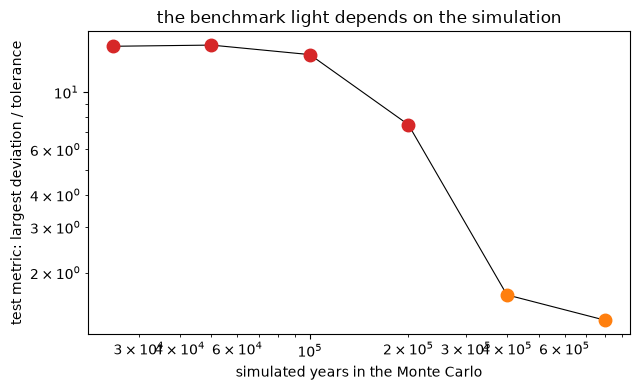

In [5]:
# Rerun the benchmark test with a growing Monte Carlo and draw its metric, coloured by the light
light_color = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
moments_tuple = (moments.mean, moments.variance, moments.skewness)
sweep = []
for n_years in (25_000, 50_000, 100_000, 200_000, 400_000, 800_000):
    losses = aggregate.simulate_annual_losses("poisson", (100.0,), "lognormal", (0.0, 2.0), n_years, 2010).losses
    q_year, se_year = aggregate.mc_quantile(losses, 0.999)
    quantiles = {"monte-carlo": q_year, "panjer": q_panjer, "fft": q_fft}
    test_year = oprisk_tests.benchmark_reproduction(moments_tuple, quantiles, moment_rel_tol=1e-5)
    sweep.append((n_years, q_year, se_year, test_year.metric, test_year.light.value))
    print("years %7d | q = %7.1f (se %6.1f) | metric %7.3f | light %s" % sweep[-1])
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.loglog([s[0] for s in sweep], [s[3] for s in sweep], "-", color="black", linewidth=0.8)
for n_years, _, _, metric, light in sweep:
    ax.loglog([n_years], [metric], "o", color=light_color[light], markersize=9)
ax.set_xlabel("simulated years in the Monte Carlo")
ax.set_ylabel("test metric: largest deviation / tolerance")
ax.set_title("the benchmark light depends on the simulation")
fig.tight_layout()
plt.show()

The metric falls as the simulation grows, which is the square-root law of notebook 01 seen through a test: with 200,000 years it is 7.476 and red, and the committed row with 1,000,000 years has 0.197 and is green. The Panjer and Fourier quantiles never changed, so the colour moved with the Monte Carlo alone. Read a red here as an under-sized simulation before reading it as an engine fault. The sweep reuses one seed; another seed would shift the points but not the downward trend.

### Step 3: threshold stability, a test on the median profile

The committed `oprisk.threshold_stability` rows belong to the splice rung of each cell and judge the **median** tail-index profile over the 1,000 histories, thresholds 1, 2, 4 and 8 times the collection threshold. Their metric is the range of those four medians. The next cell reads the medians of the cell with 10 years and a threshold of EUR 20,000, runs the engine's test on them and compares it with the committed row; then it sets the range of the single history of notebook 02 beside it.

In [6]:
# The threshold-stability test on the committed median profile, and on the single history of notebook 02
cell = next(c for c in docs["xi-0-8"]["outputs"]["cells"] if c["id"] == "y10-h20000")
thresholds = np.array([row["threshold_eur"] for row in cell["threshold_stability"]])
medians = np.array([row["tail_index"]["median"] for row in cell["threshold_stability"]])
median_test = oprisk_tests.threshold_stability(thresholds, medians, model_id="lda-splice")
committed_row = next(
    r for r in docs["xi-0-8"]["tests"] if r[
        "test_id"
    ] == "oprisk.threshold_stability" and r["segment"] == "y10-h20000"
)
print(
    "median profile:", np.round(medians, 4),
    "| range %.5f, light %s | committed %.5f, %s" % (
        median_test.metric, median_test.light.value, committed_row["metric"], committed_row["light"]
    )
)
variant = generator.variant(0.8)
one = generator.draw_history(variant, 4208002, 10).recorded(20_000.0)
profile = distributions.tail_index_profile(one.amounts, thresholds)
single = oprisk_tests.threshold_stability(
    profile.thresholds, np.where(profile.converged, profile.xi, np.nan), model_id="lda-splice"
)
print(
    "single history (seed 4208002): xi = %s | range %.4f, light %s" % (
        np.round(profile.xi, 3), single.metric, single.light.value
    )
)

median profile: [0.799  0.7924 0.7864 0.7796] | range 0.01941, light green | committed 0.01941, green
single history (seed 4208002): xi = [0.803 0.914 0.882 0.874] | range 0.1104, light amber


### Step 4: capital stability, the test the case is built around

The test takes the 99.9% capital of one rung on many independent histories and the true quantile. Its metric is the dispersion $(p_{75} - p_{25}) / \text{truth}$ and its statistic the bias $\text{median}/\text{truth} - 1$; the light is the worse of the two against gates of 0.25 and 0.50 for the dispersion and 0.10 and 0.25 for the absolute bias. The committed rows use 1,000 histories per cell. Here we run the case's own estimator on the first 40 histories of the cell with tail index 0.8, 10 years and threshold EUR 20,000, whose seeds are those of the committed cell (about 15 seconds), compute the test for four rungs, and print the committed row beside it.

In [7]:
# Estimate 40 independent histories with the case's estimator and run the capital-stability test on four rungs
first_seed, n_histories = generator.cell_seeds(42, 1, 3, 40)
bi = docs["xi-0-8"]["outputs"]["bank"]["business_indicator"]["bi_eur"]
runs = [replicate.estimate(variant, first_seed + k, 10, 20_000.0, bi, None, 20_000) for k in range(n_histories)]
true_quantile = docs["xi-0-8"]["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
stable_rows = [
    t for t in docs["xi-0-8"]["tests"] if t["test_id"] == "oprisk.capital_stability" and t["segment"] == "y10-h20000"
]
rows, committed_by_rung = {}, {}
print(
    "%-26s %5s %10s %8s %8s | %s" % (
        "rung", "n", "dispersion", "bias", "light", "committed over 1000: dispersion, bias, light"
    )
)
for rung in ("lda_lognormal", "lda_lognormal_truncated", "lda_splice", "sla"):
    capitals = np.array([r[rung] for r in runs])
    capitals = capitals[np.isfinite(capitals)]
    result = oprisk_tests.capital_stability(capitals, true_quantile, model_id=rung)
    committed = next(t for t in stable_rows if t["model_id"] == rung.replace("_", "-"))
    rows[rung] = result
    committed_by_rung[rung] = (committed["metric"], committed["statistic"])
    print(
        "%-26s %5d %10.3f %+8.3f %8s | %.3f %+.3f %s" % (
            rung, capitals.size, result.metric, result.statistic, result.light.value, *committed_by_rung[rung],
            committed["light"]
        )
    )

rung                           n dispersion     bias    light | committed over 1000: dispersion, bias, light
lda_lognormal                 40      0.007   -0.957      red | 0.008 -0.958 red
lda_lognormal_truncated       37      0.322   -0.685      red | 0.275 -0.738 red
lda_splice                    28      2.347   +0.511      red | 1.983 -0.091 red
sla                           40      1.234   +0.199      red | 1.020 -0.037 red


The next cell draws the four rungs side by side: the dispersion and the bias of the capital on our 40 histories next to the committed values over 1,000, the two numbers the test turns into a colour.

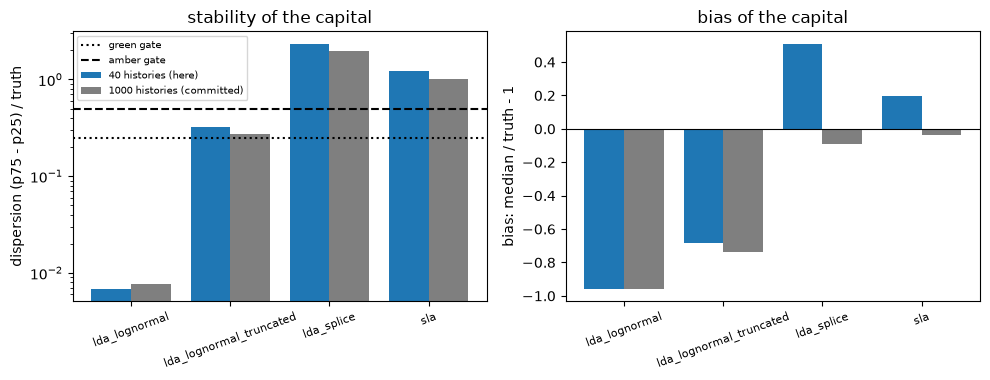

In [8]:
# Draw the dispersion and the bias of each rung on 40 histories against the committed values over 1,000
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
names = list(rows)
pos = np.arange(len(names))
left.bar(pos - 0.2, [rows[n].metric for n in names], 0.4, label="40 histories (here)", color="tab:blue")
left.bar(pos + 0.2, [committed_by_rung[n][0] for n in names], 0.4, label="1000 histories (committed)", color="tab:gray")
left.set_yscale("log")
left.axhline(0.25, color="black", linestyle=":", label="green gate")
left.axhline(0.50, color="black", linestyle="--", label="amber gate")
left.set_xticks(pos)
left.set_xticklabels(names, rotation=20, fontsize=8)
left.set_ylabel("dispersion (p75 - p25) / truth")
left.set_title("stability of the capital")
left.legend(fontsize=7)
right.bar(pos - 0.2, [rows[n].statistic for n in names], 0.4, color="tab:blue")
right.bar(pos + 0.2, [committed_by_rung[n][1] for n in names], 0.4, color="tab:gray")
right.axhline(0.0, color="black", linewidth=0.8)
right.set_xticks(pos)
right.set_xticklabels(names, rotation=20, fontsize=8)
right.set_ylabel("bias: median / truth - 1")
right.set_title("bias of the capital")
fig.tight_layout()
plt.show()

The lognormal that ignores the threshold is the one case where dispersion is tiny, 0.007 here and 0.008 over 1,000 histories, and the bias is almost -1, 96% too low: stable and wrong. The splice and the approximation have the opposite problem, dispersions of 2.347 and 1.234 against gates of 0.25 and 0.50 and a bias that changes sign between 40 and 1,000 histories (+0.511 against -0.091 for the splice). The forty histories are enough to see which rung fails and why, not to measure its bias; the committed bars are the measurement.

### Step 5: the gates are a choice

The metric does not change when a gate does; the light does. The next cell re-runs the same test on the splice capitals with gates ten times wider on the dispersion and the bias (green at 2.5 and 1.0, amber at 5.0 and 2.5) and prints how the light moves. It is the reason a reader of a row must read its gates: a green with gates that wide says almost nothing.

In [9]:
# The same capitals with gates ten times wider: the metric stays, the light moves
splice_capitals = np.array([r["lda_splice"] for r in runs])
splice_capitals = splice_capitals[np.isfinite(splice_capitals)]
wide = oprisk_tests.capital_stability(
    splice_capitals, true_quantile, model_id="lda_splice", dispersion_green=2.5, dispersion_amber=5.0, bias_green=1.0,
    bias_amber=2.5
)
print(
    "gates of the case: %s -> metric %.3f, light %s" % (
        rows["lda_splice"].extras["thresholds"], rows["lda_splice"].metric, rows["lda_splice"].light.value
    )
)
print("gates ten times wider: %s -> metric %.3f, light %s" % (wide.extras["thresholds"], wide.metric, wide.light.value))

gates of the case: {'dispersion_green': 0.25, 'dispersion_amber': 0.5, 'bias_green': 0.1, 'bias_amber': 0.25} -> metric 2.347, light red
gates ten times wider: {'dispersion_green': 2.5, 'dispersion_amber': 5.0, 'bias_green': 1.0, 'bias_amber': 2.5} -> metric 2.347, light green


### Step 6: the response of the SMA and the influence of scenarios, in the four variants

The last two tests apply to a single history and a single set of scenarios per variant. The next cell regenerates, for each variant, the history behind the committed `sma_response` block and runs `oprisk.sma_ilm_response` with a loss of half the component added; then it runs `oprisk.scenario_influence` on the committed influences. Both are compared with the committed rows.

In [10]:
# Run the SMA response and scenario-influence tests in the four variants
print("%-8s %-24s %10s %8s | %10s %8s" % ("", "", "recomputed", "", "committed", ""))
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(
        generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10
    ).recorded(20_000.0)
    response_test = oprisk_tests.sma_ilm_response(
        block["bic_eur"], history.annual, 0.5 * block["bic_eur"], model_id="sma"
    )
    committed_response = next(t for t in doc["tests"] if t["test_id"] == "oprisk.sma_ilm_response")
    influences = np.array([s["influence"] for s in doc["outputs"]["scenario_influence"]["scenarios"]])
    influence_test = oprisk_tests.scenario_influence(influences, model_id="scenario")
    committed_influence = next(t for t in doc["tests"] if t["test_id"] == "oprisk.scenario_influence")
    print(
        "%-8s %-24s %10.4f %8s | %10.4f %8s" % (
            name, "sma_ilm_response", response_test.metric, response_test.light.value, committed_response["metric"],
            committed_response["light"]
        )
    )
    print(
        "%-8s %-24s %10.4f %8s | %10.4f %8s" % (
            name, "scenario_influence", influence_test.metric, influence_test.light.value,
            committed_influence["metric"], committed_influence["light"]
        )
    )

                                  recomputed          |  committed         
xi-0-6   sma_ilm_response             0.2753      red |     0.2753      red
xi-0-6   scenario_influence           0.1652    amber |     0.1652    amber
xi-0-8   sma_ilm_response             0.2520      red |     0.2520      red
xi-0-8   scenario_influence           0.0828    green |     0.0828    green
xi-0-96  sma_ilm_response             0.2314      red |     0.2314      red
xi-0-96  scenario_influence           0.0926    green |     0.0926    green
xi-1-1   sma_ilm_response             0.2518      red |     0.2518      red
xi-1-1   scenario_influence           0.1481    amber |     0.1481    amber


The last cell shows all the committed capital-stability rows at once. Each point is a rung in a cell of a variant: its dispersion on the horizontal axis (logarithmic) and the absolute bias on the vertical one, with the gates of the case drawn as lines. Almost every point lies in the red zone, for different reasons: the lognormal rung has a tiny dispersion and a bias of almost -1 (it is stable and wrong), the splice and approximation rungs have a dispersion of order 1 or more and a median much closer to the truth (about 0.6 to 1.0 times it): closer on average, and unstable.

capital-stability rows: 92 | red: 92


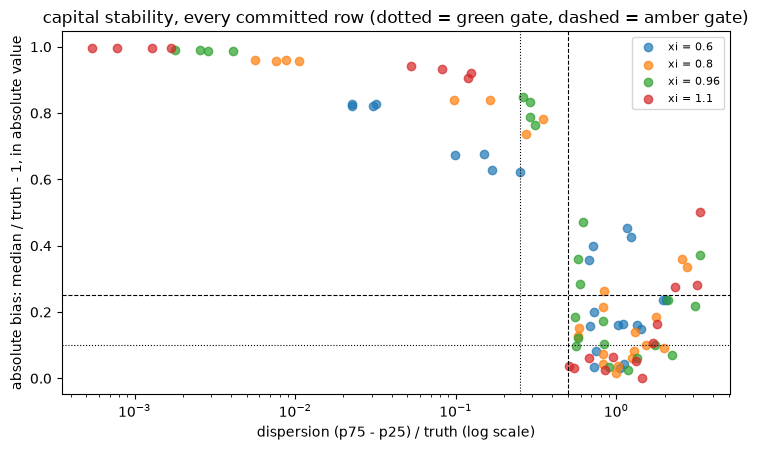

In [11]:
# Draw dispersion against absolute bias for every committed capital-stability row
fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = {"xi-0-6": "tab:blue", "xi-0-8": "tab:orange", "xi-0-96": "tab:green", "xi-1-1": "tab:red"}
for name, doc in docs.items():
    rows_c = [t for t in doc["tests"] if t["test_id"] == "oprisk.capital_stability"]
    ax.scatter(
        [t["metric"] for t in rows_c], [abs(t["statistic"]) for t in rows_c], color=colors[name], alpha=0.7,
        label="xi = " + str(doc["outputs"]["tail_index"])
    )
for gate, style in ((0.25, ":"), (0.50, "--")):
    ax.axvline(gate, color="black", linestyle=style, linewidth=0.8)
for gate, style in ((0.10, ":"), (0.25, "--")):
    ax.axhline(gate, color="black", linestyle=style, linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("dispersion (p75 - p25) / truth (log scale)")
ax.set_ylabel("absolute bias: median / truth - 1, in absolute value")
ax.set_title("capital stability, every committed row (dotted = green gate, dashed = amber gate)")
ax.legend(fontsize=8)
all_rows = [r for doc in docs.values() for r in doc["tests"] if r["test_id"] == "oprisk.capital_stability"]
print("capital-stability rows:", len(all_rows), "| red:", sum(r["light"] == "red" for r in all_rows))
fig.tight_layout()
plt.show()

Almost every point sits in the red region, for two different reasons that the two axes separate. The lognormal rung of every variant hugs the left edge with a bias near 1: it is stable and wrong. The other rungs spread to the right, with dispersions from 0.3 to several, because ten years of heavy-tailed losses do not fix the capital. The figure shows the committed rows only; it does not show whether more history would move the points into the green region, which the level 4 notebook measures.

## Results

**Answer:** Each test is a metric set against gates that travel with the row, never a p-value, and the colour depends on more than the method: the benchmark reproduction is red with a metric of 7.476 on a Monte Carlo of 200,000 years and green at 0.197 on 1,000,000, the splice capital has a dispersion of 2.347 that turns green when the gates are ten times wider, and the threshold-stability range is 0.01941 on the median profile (green) but 0.1104 on one history (amber). Read every light with its gates, its simulation and its history.

- **No p-values.** All 120 committed rows of the four variants (31, 31, 31 and 27) have an empty p-value: the lights compare a metric with gates the case sets.
- **The benchmark and the years.** The reproduction test with a Monte Carlo of 200,000 years gives a quantile of 6,290.7 with a standard error of 263.7, a metric of 7.476 and a red light, where the committed row, with 1,000,000 years, has 0.197 and is green. The test judges the simulation as much as the engine.
- **Threshold stability.** The test run on the committed median profile (0.799, 0.792, 0.786, 0.780) has a range of 0.0194 and is green, equal to the committed row; on the single history of notebook 02 the range is 0.1104 and the light is amber. A green row of this test says the **median** profile is flat, not that a bank's one history is.
- **Capital stability.** On 40 histories the lognormal that ignores the threshold has a dispersion of 0.007 and a bias of -0.957, stable and 96% too low, the committed row on 1,000 histories being 0.008 and -0.958. The truncated lognormal (0.322, -0.685), the splice (2.347, +0.511 on the 28 histories where it is defined) and the approximation (1.234, +0.199) are red, against 0.275, 1.983 and 1.020 on 1,000 histories. With 40 histories the bias of the unstable rungs is itself unstable: the splice shows +0.511 where the committed median is -0.091.
- **The gates are a choice.** The same splice capitals with gates ten times wider have the same metric, 2.347, and a green light. Every light has to be read with its gates, carried in the row.
- **The other two tests.** The SMA response is red in all four variants (metrics 0.275, 0.252, 0.231 and 0.252 above the amber gate of 0.15) and the scenario influence is amber at tail indices 0.6 and 1.1 (0.165 and 0.148) and green at 0.8 and 0.96 (0.083 and 0.093); the recomputation equals the committed rows to four decimals in the four variants.
- **The whole table.** In the figure, 92 of the 92 committed capital-stability rows (24, 24, 24 and 20) are red: the lognormal rung because it is biased, the others because they are dispersed.

What this notebook does not show: what the dispersion means for the choice between the LDA and the SMA (notebook 07), or how the dispersion depends on the history length and the tail index (the level 4 notebook).

## Summary

- The five operational-risk tests are descriptive: a metric against gates that Contraste sets, no p-value, and the gates travel in each row.
- The same metric gives different lights under different gates, and the benchmark test turns red when its Monte Carlo has too few years.
- The threshold-stability row judges the median profile; one history can drift much more.
- On the committed grid every capital-stability row is red, some because the rung is biased and some because it is dispersed.

**What to try next.** Change the number of histories in step 4 from 40 to 100 (about 45 seconds) and see how the splice bias settles toward the committed value. Change the gates of `threshold_stability` to 0.25 and 0.5 and see the single history turn green. Continue with notebook 07.

## References

- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Chavez-Demoulin, V., Embrechts, P. and Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 and https://doi.org/10.21314/JOP.2010.077
- Shevchenko, P. V. and Wuthrich, M. V. (2006), The structural modeling of operational risk via Bayesian inference, Journal of Operational Risk 1(3), 3-26. https://doi.org/10.21314/JOP.2006.016